In [ ]:
import numpy as np
from fit_file import X_sq
import matplotlib.pyplot as plt
import sympy as sp

In [ ]:
#data inladen
A1 = [0.281, 0.583, 0.840, 1.10]
A2 = [0.295, 0.582, 0.840, 1.10]
A = np.array([])
for i in range(len(A1)):
    A = np.append(A, (A1[i] + A2[i])/2)

dA= A *2/100

concentraties = [3.00e-6, 6.00e-6,9.00e-6,12.0e-6]
print(dA)

[0.00576 0.01165 0.0168  0.022  ]


In [ ]:
##fouten

def fout_con_opl_2_4 (V_1, c_1, V_2, dv_1 , dc_1, dv_2):
    v1 , c1 , v2 = sp.symbols('v1 c1 v2')
    c2= (v1*c1)/v2
    s_func = sp.sqrt((sp.diff(c2, v1))**2 * dv_1**2 + (sp.diff(c2, c1))**2 * dc_1**2 + (sp.diff(c2, v2))**2 * dv_2**2)
    s= s_func.subs([(v1, V_1) , (c1, c_1) , (v2, V_2)])
    return s

def fout_con_opl_1_3 (V_1, c_1, V_w, dv_1 , dc_1, dv_w):
    v1 , c1 , vw = sp.symbols('v1 c1 vw')
    c2= (v1*c1)/(vw+v1)
    s_func = sp.sqrt((sp.diff(c2, v1))**2 * dv_1**2 + (sp.diff(c2, c1))**2 * dc_1**2 + (sp.diff(c2, vw))**2 * dv_w**2)
    s= s_func.subs([(v1, V_1) , (c1, c_1) , (vw, V_w)])
    return s

fouten_concentratie = []
c_1 = 6.00e-5
dc_1 = 5e-7
#fout oplossing 1

v_11 = 3.0e-3
dv_11 = 0.1e-3

v_1w = 57.0e-3
dv_1w = 0.05e-3

dc_21 = fout_con_opl_1_3(v_11, c_1, v_1w, dv_11, dc_1 , dv_1w)
fouten_concentratie.append(dc_21)

#fout oplossing 2
v_12 = 10e-3
dv_12 = 0.02e-3

v_22 = 100e-3
dv_22 = 0.10e-3

dc_22 = fout_con_opl_2_4(v_12,c_1,v_22,dv_12, dc_1, dv_22)
fouten_concentratie.append(dc_22)


#fout oplossing 3

v_13 = 6.0e-3
dv_13 = 0.1e-3

v_3w = 34.0e-3
dv_3w = 0.05e-3

dc_23 = fout_con_opl_1_3(v_13,c_1,v_3w,dv_13, dc_1 , dv_3w)
fouten_concentratie.append(dc_23)

#fout oplossing 4
v_14 = 20e-3
dv_14 = 0.02e-3

v_24 = 100e-3
dv_24 = 0.10e-3

dc_24 = fout_con_opl_2_4(v_14,c_1,v_24,dv_14, dc_1, dv_24)
fouten_concentratie.append(dc_24)
print(fouten_concentratie)

[9.82662200351677e-8, 5.17687164221791e-8, 1.48350303336394e-7, 1.01429778664848e-7]



---------START--------------------------------------------------------------------------------------------------


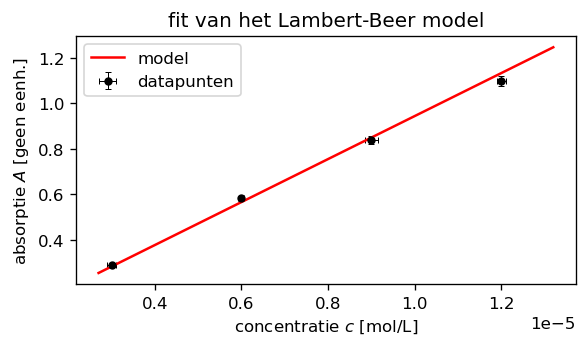

For parameter epsilon  :     Minimum at   94423.55894834     ;     68% CI = [  93484.33065738,   95362.82009206]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min           5.15301474
Reduced χ² value       :     χ²_red           1.71767158
P-value                :     p-value          0.16092948


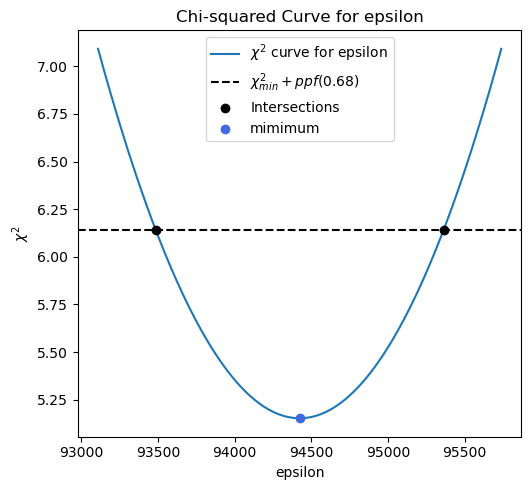

----------END---------------------------------------------------------------------------------------------------



In [ ]:
def model_lambert (params , s):
    epsilon = params
    return epsilon * s
    
#fit
param_names = ["epsilon"]
x =np.array(concentraties).astype(float)
dx = np.array(fouten_concentratie).astype(float)
y = A.astype(float)
dy = dA.astype(float)

x_label = r"concentratie $c$ [mol/L]"
y_label = r"absorptie $A$ [geen eenh.]"
title = r"fit van het Lambert-Beer model"

X_sq(((x, dx), (y, dy)), param_names, [94423.55894834], model_lambert, graf1_x_label = x_label, graf1_y_label = y_label, graf1_title=title)

7.598739212875369e-06
1.69733207828715e-7


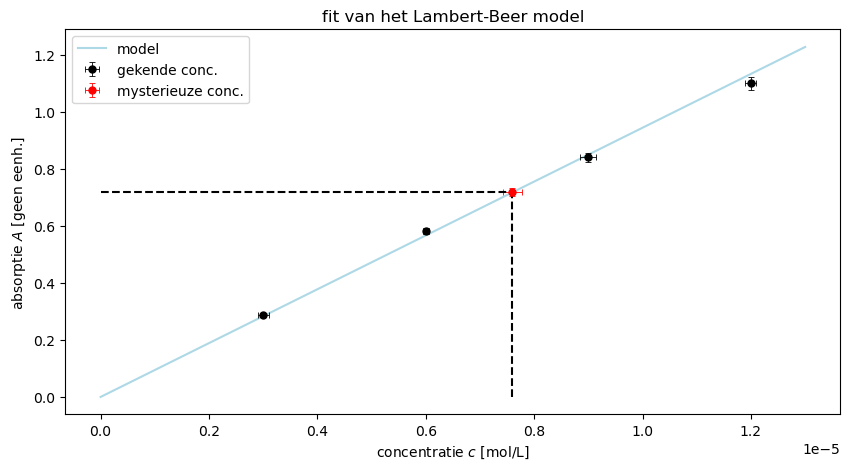

In [ ]:
def fout_cM(a, e, da, de):
    A, eps = sp.symbols("A eps")
    cM = A / eps
    s_func = sp.sqrt(sp.diff(cM, A)**2 * da**2 + sp.diff(cM, eps)**2 * de**2)
    return s_func.subs([(A, a), (eps, e)])

fig, ax = plt.subplots(figsize = (10, 5))
X = np.linspace(0, 13e-6, 1000)
Y = 94423.55894834 * X
ax.plot(X, Y, color = 'lightblue', label = 'model')
ax.errorbar(x, y, xerr=dx, yerr=dy, label="gekende conc.",
                marker="o", markersize=5, fmt=" ", color="black", ecolor="black", capsize=2, capthick=0.6, linewidth=0.6)
AM = 0.7175
xM = AM / 94423.55894834
ax.errorbar(xM, AM, xerr = fout_cM(AM, 94423.55894834, 0.02*AM, 939.23), yerr=0.02*AM, label="mysterieuze conc.",
                marker="o", markersize=5, fmt=" ", color="red", ecolor="red", capsize=2, capthick=0.6, linewidth=0.6)

ax.vlines(x = xM, ymin = 0, ymax = AM, ls = '--', color = 'black')
ax.hlines(y = AM, xmin = 0, xmax = xM, ls = '--', color = 'black')
ax.legend()
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
ax.set_title(title)
print(xM)
print(fout_cM(AM, 94423.55894834, 0.02*AM, 939.23))

